Import bibliotek i przygotowania odczytu danych

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

dane = pd.read_csv("train.csv")
oryginal = dane.copy(deep=True)
print("Wymiary:", dane.shape)
display(dane.head())

Wymiary: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Przedstawienie typów danych w pliku, staystyki danych i strutkura zbioru

In [3]:
print("Typy:", dane.dtypes.value_counts(), sep="\n")
print("Duplikaty wierszy:", dane.duplicated().sum())
print("Duplikaty identyfikatora:", dane["Id"].duplicated().sum())
display(dane.describe().T)
display(dane.describe(include="object").T.head(25))
print("Braki w SalePrice:", dane["SalePrice"].isna().sum())

Typy:
str        43
int64      35
float64     3
Name: count, dtype: int64
Duplikaty wierszy: 0
Duplikaty identyfikatora: 0


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_14836\3888458196.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(dane.describe(include="object").T.head(25))


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


Braki w SalePrice: 0


Brakujace dane w liczbie i procentach

,liczba,procent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Wszystkie brakujące komórki: 7829
Kolumny z brakami: 19
Kompletne wiersze: 0


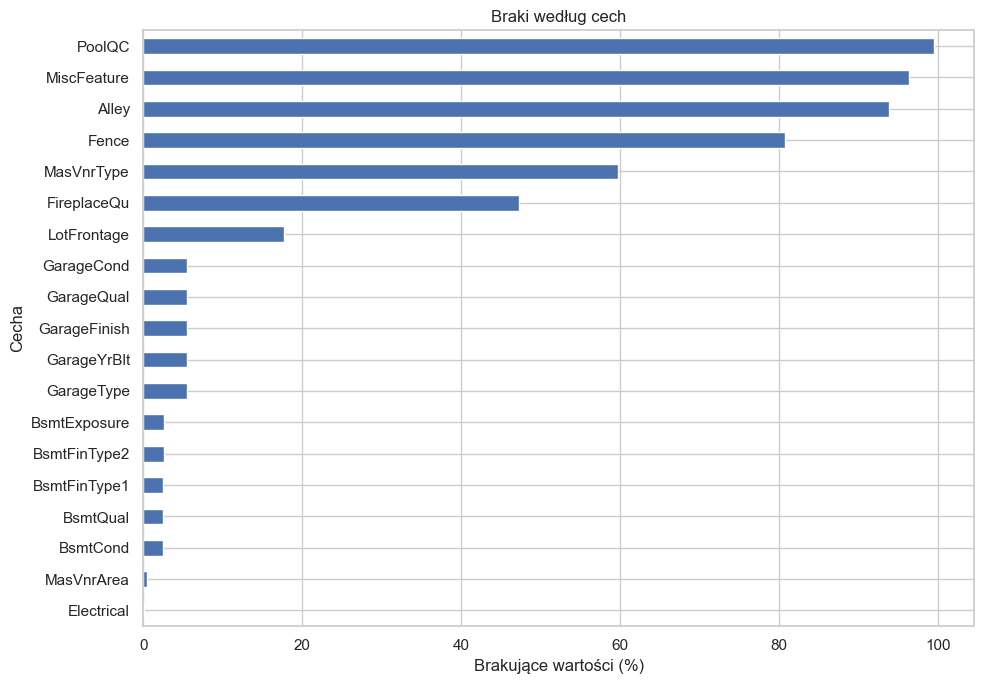

In [4]:
braki = pd.DataFrame({"liczba": dane.isna().sum(),
                       "procent": 100 * dane.isna().mean()})
braki = braki.query("liczba > 0").sort_values("procent", ascending=False)
display(braki.round(2))
print("Wszystkie brakujące komórki:", int(dane.isna().sum().sum()))
print("Kolumny z brakami:", len(braki))
print("Kompletne wiersze:", len(dane.dropna()))
fig, ax = plt.subplots(figsize=(10, 7))
braki.sort_values("procent")["procent"].plot.barh(ax=ax)
ax.set(xlabel="Brakujące wartości (%)", ylabel="Cecha", title="Braki według cech")
plt.tight_layout()
plt.show()

Graf przedstawiający mapę braków i ich współwystępowanie

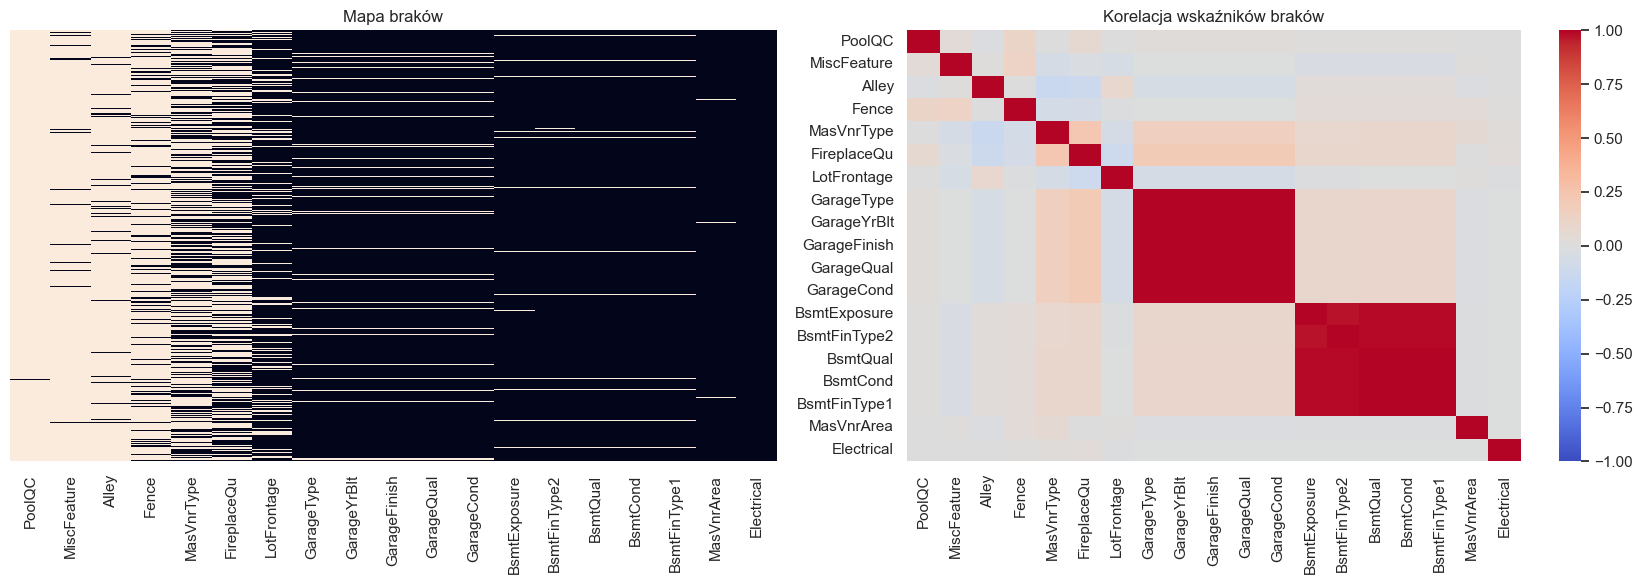

,PoolQC,MiscFeature,Alley,Fence,MasVnrType,FireplaceQu,LotFrontage,GarageType,GarageYrBlt,GarageFinish,GarageQual,GarageCond,BsmtExposure,BsmtFinType2,BsmtQual,BsmtCond,BsmtFinType1,MasVnrArea,Electrical
PoolQC,1.00,0.04,-0.02,0.12,0.00,0.07,0.01,0.02,0.02,0.02,0.02,0.02,0.01,0.01,0.01,0.01,0.01,0.01,0.00
MiscFeature,0.04,1.00,0.01,0.13,-0.06,-0.03,-0.05,-0.00,-0.00,-0.00,-0.00,-0.00,-0.04,-0.04,-0.04,-0.04,-0.04,0.01,0.01
Alley,-0.02,0.01,1.00,0.00,-0.14,-0.12,0.08,-0.05,-0.05,-0.05,-0.05,-0.05,0.02,0.02,0.02,0.02,0.02,-0.02,0.01
Fence,0.12,0.13,0.00,1.00,-0.07,-0.06,-0.01,-0.00,-0.00,-0.00,-0.00,-0.00,0.04,0.04,0.03,0.03,0.03,0.04,0.01
MasVnrType,0.00,-0.06,-0.14,-0.07,1.00,0.23,-0.06,0.16,0.16,0.16,0.16,0.16,0.08,0.08,0.09,0.09,0.09,0.06,0.02
FireplaceQu,0.07,-0.03,-0.12,-0.06,0.23,1.00,-0.12,0.20,0.20,0.20,0.20,0.20,0.09,0.09,0.09,0.09,0.09,0.00,0.03
LotFrontage,0.01,-0.05,0.08,-0.01,-0.06,-0.12,1.00,-0.06,-0.06,-0.06,-0.06,-0.06,-0.01,-0.01,-0.01,-0.01,-0.01,0.01,-0.01
GarageType,0.02,-0.00,-0.05,-0.00,0.16,0.20,-0.06,1.00,1.00,1.00,1.00,1.00,0.09,0.09,0.09,0.09,0.09,-0.02,-0.01
GarageYrBlt,0.02,-0.00,-0.05,-0.00,0.16,0.20,-0.06,1.00,1.00,1.00,1.00,1.00,0.09,0.09,0.09,0.09,0.09,-0.02,-0.01
GarageFinish,0.02,-0.00,-0.05,-0.00,0.16,0.20,-0.06,1.00,1.00,1.00,1.00,1.00,0.09,0.09,0.09,0.09,0.09,-0.02,-0.01


In [5]:
cols = braki.index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(dane[cols].isna(), cbar=False, yticklabels=False, ax=ax[0])
ax[0].set_title("Mapa braków")
wsp = dane[cols].isna().astype(int).corr()
sns.heatmap(wsp, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Korelacja wskaźników braków")
plt.tight_layout()
plt.show()
display(wsp.round(2))

Wartość nie istnienia jako NA

In [6]:
testy = {
    "garaż": ("GarageType", "GarageCars"),
    "piwnica": ("BsmtQual", "TotalBsmtSF"),
    "kominek": ("FireplaceQu", "Fireplaces"),
    "basen": ("PoolQC", "PoolArea")
}
for nazwa, (cecha, ilosc) in testy.items():
    print("\n", nazwa, "—", cecha, "vs", ilosc)
    display(pd.crosstab(dane[cecha].isna(), dane[ilosc].eq(0),
                        rownames=["brak opisu"], colnames=["wartość 0"]))


 garaż — GarageType vs GarageCars


wartość 0,False,True
brak opisu,,
False,1379,0
True,0,81



 piwnica — BsmtQual vs TotalBsmtSF


wartość 0,False,True
brak opisu,,
False,1423,0
True,0,37



 kominek — FireplaceQu vs Fireplaces


wartość 0,False,True
brak opisu,,
False,770,0
True,0,690



 basen — PoolQC vs PoolArea


wartość 0,False,True
brak opisu,,
False,7,0
True,0,1453


Od czego zależy brak danych

,n,mediana_ceny,mediana_powierzchni,srednia_jakosc
LotFrontage_brak,,,,
0,1201,159500.0,9262.0,6.122398
1,259,172400.0,10624.0,5.992278


LotFrontage_brak,znane %,brak %
Neighborhood,,
Blmngtn,82.4,17.6
Blueste,100.0,0.0
BrDale,100.0,0.0
BrkSide,87.9,12.1
ClearCr,46.4,53.6
CollgCr,84.0,16.0
Crawfor,80.4,19.6
Edwards,92.0,8.0
Gilbert,62.0,38.0


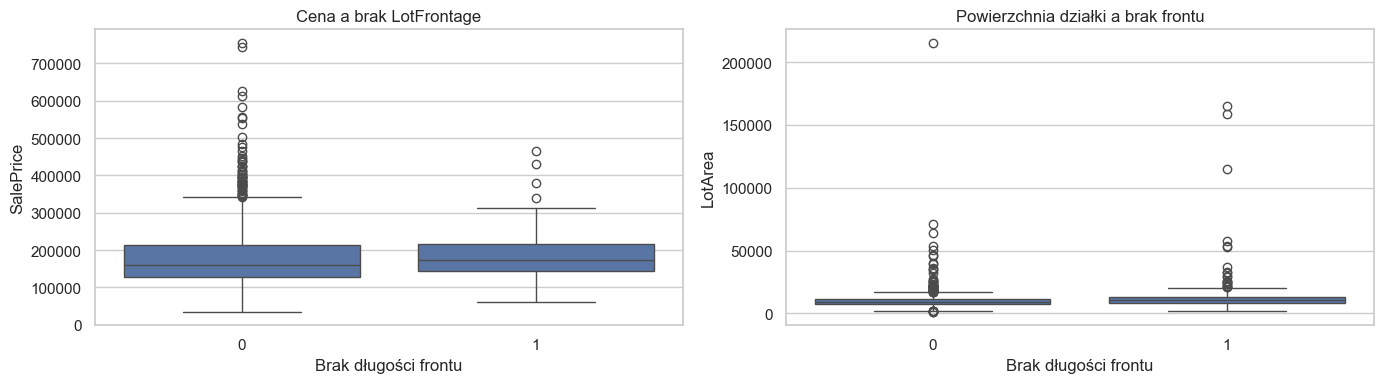

In [7]:
dane["LotFrontage_brak"] = dane["LotFrontage"].isna().astype(int)
display(dane.groupby("LotFrontage_brak").agg(
    n=("Id", "size"),
    mediana_ceny=("SalePrice", "median"),
    mediana_powierzchni=("LotArea", "median"),
    srednia_jakosc=("OverallQual", "mean")
))
display(pd.crosstab(dane["Neighborhood"], dane["LotFrontage_brak"],
                    normalize="index").mul(100).round(1).rename(columns={0:"znane %",1:"brak %"}))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=dane, x="LotFrontage_brak", y="SalePrice", ax=ax[0])
ax[0].set(title="Cena a brak LotFrontage", xlabel="Brak długości frontu")
sns.boxplot(data=dane, x="LotFrontage_brak", y="LotArea", ax=ax[1])
ax[1].set(title="Powierzchnia działki a brak frontu", xlabel="Brak długości frontu")
plt.tight_layout()
plt.show()

Mediana globalna a mediana dzielnicy

,oryginal,mediana_globalna,mediana_dzielnicy
count,1201.00,1460.00,1460.00
mean,70.05,69.86,70.20
std,24.28,22.03,22.43
min,21.00,21.00,21.00
25%,59.00,60.00,60.00
50%,69.00,69.00,70.00
75%,80.00,79.00,80.00
max,313.00,313.00,313.00


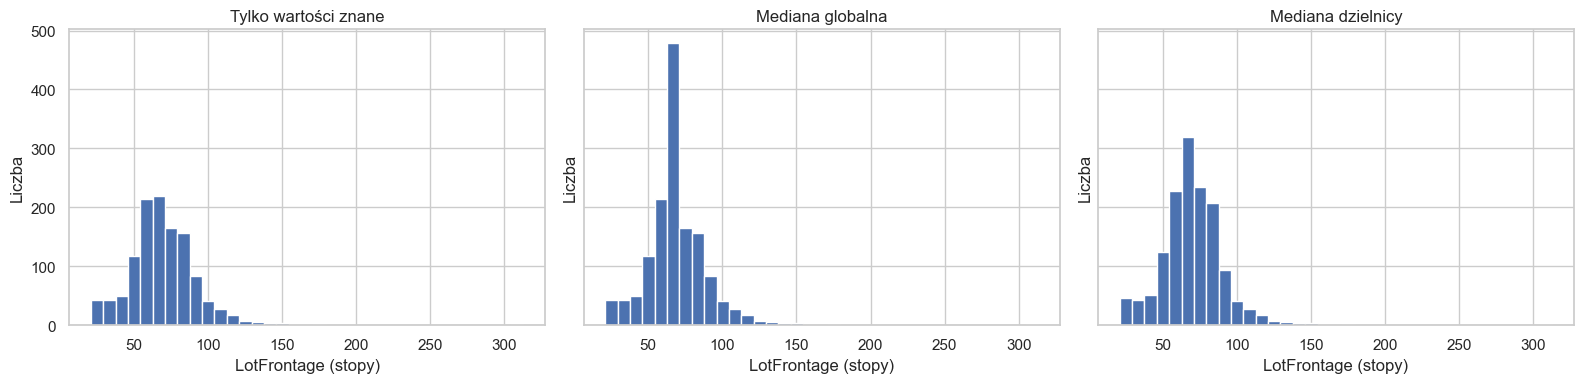

In [8]:
imputacje = pd.DataFrame(index=oryginal.index)
imputacje["oryginal"] = oryginal["LotFrontage"]
imputacje["mediana_globalna"] = oryginal["LotFrontage"].fillna(oryginal["LotFrontage"].median())
grupowe = oryginal.groupby("Neighborhood")["LotFrontage"].transform("median")
imputacje["mediana_dzielnicy"] = oryginal["LotFrontage"].fillna(grupowe).fillna(oryginal["LotFrontage"].median())
display(imputacje.describe().round(2))
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (kol, tytul) in zip(axes, [
    ("oryginal", "Tylko wartości znane"),
    ("mediana_globalna", "Mediana globalna"),
    ("mediana_dzielnicy", "Mediana dzielnicy")]):
    ax.hist(imputacje[kol].dropna(), bins=35)
    ax.set(title=tytul, xlabel="LotFrontage (stopy)", ylabel="Liczba")
plt.tight_layout()
plt.show()

Skutki bezmyślnego usuwania danych

In [10]:
warianty = {
    "pełne dane": dane,
    "usuń brak LotFrontage": dane.dropna(subset=["LotFrontage"]),
    "usuń brak Electrical": dane.dropna(subset=["Electrical"]),
    "usuń dowolny brak": dane.dropna()
}
porownanie_usuwania = pd.DataFrame({
    nazwa: {"wiersze": len(d), "odsetek_zachowanych":100*len(d)/len(dane),
            "mediana_SalePrice":d["SalePrice"].median(),
            "srednia_OverallQual":d["OverallQual"].mean()}
    for nazwa, d in warianty.items()
}).T
display(porownanie_usuwania.round(2))

,wiersze,odsetek_zachowanych,mediana_SalePrice,srednia_OverallQual
pełne dane,1460.0,100.00,163000.0,6.10
usuń brak LotFrontage,1201.0,82.26,159500.0,6.12
usuń brak Electrical,1459.0,99.93,163000.0,6.10
usuń dowolny brak,0.0,0.00,NaN,NaN


Odpowiedzi do zadań z prezentacji które nie zostały przedstawione wcześniej.

Min: 34900
Max: 755000
Średnia: 180921.19589041095
Mediana: 163000.0
Q1: 129975.0
Q3: 214000.0
IQR: 84025.0


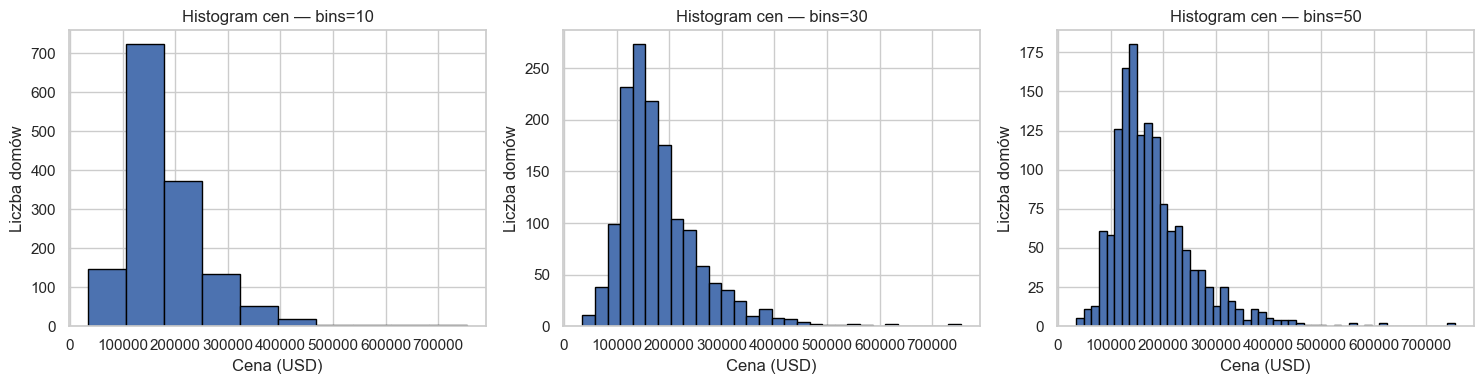

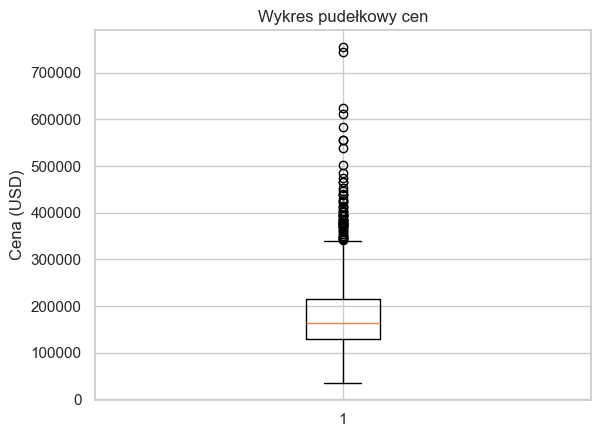

In [11]:
ceny = dane["SalePrice"]

print("Min:", ceny.min())
print("Max:", ceny.max())
print("Średnia:", ceny.mean())
print("Mediana:", ceny.median())

q1 = ceny.quantile(0.25)
q3 = ceny.quantile(0.75)
iqr = q3 - q1

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, bins in zip(axes, [10, 30, 50]):
    ax.hist(ceny, bins=bins, edgecolor="black")
    ax.set_title(f"Histogram cen — bins={bins}")
    ax.set_xlabel("Cena (USD)")
    ax.set_ylabel("Liczba domów")

plt.tight_layout()
plt.show()

plt.boxplot(ceny)
plt.title("Wykres pudełkowy cen")
plt.ylabel("Cena (USD)")
plt.show()

Odpowiedzi na pytania:

Jaki jest rozkład cen? 
Prawostronnie skośny — większość domów ma niższe lub umiarkowane ceny, natomiast niewielka liczba bardzo drogich nieruchomości wydłuża prawy ogon rozkładu.

Czy są wartości odstające? 
Tak. Według reguły 1,5 × IQR jest 61 domów z cenami powyżej górnej granicy 340 037,50 USD. Mogą to być duże, luksusowe domy w atrakcyjnych lokalizacjach, a niekoniecznie błędy danych.

Jaka jest średnia i mediana? 
Średnia wynosi około 180 921 USD, a mediana 163 000 USD. Średnia jest wyższa, ponieważ bardzo drogie domy podnoszą jej wartość.

Czy ceny mają rozkład normalny? 
Nie. Rozkład jest wyraźnie asymetryczny, a jego skośność wynosi około 1,88